# LAB 09 — NER Fine-tuning và Information Extraction

Dataset: CoNLL-2003. Alignment strategy dùng label ở subword đầu tiên; special tokens và các continuation subwords nhận `-100`. Chạy cell theo thứ tự để xem dữ liệu, baseline, model, metrics và lỗi.

## 1. Imports, model và cấu hình

In [1]:
import os
os.environ['OMP_NUM_THREADS']='1'
os.environ['MKL_NUM_THREADS']='1'
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['TOKENIZERS_PARALLELISM']='false'
import copy
import gc
import random
import sys
import time
from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support
from torch.utils.data import DataLoader
from datasets import load_dataset
from transformers import AutoModelForTokenClassification, AutoTokenizer, logging as transformers_logging

PROJECT_DIR=next((p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents) if (p/'data'/'IMDB Dataset.csv').exists()),None)
if PROJECT_DIR is None: PROJECT_DIR=Path.cwd().resolve().parent
LAB_DIR=PROJECT_DIR/'lab09'
sys.path.insert(0,str(LAB_DIR))
from baseline_ner import evaluate_baseline, train_baseline
from information_extraction import (ENTITY_TYPES,bio_to_spans,entity_length_metrics,
    entity_metrics,entities_to_dict,evaluate_information_extraction,find_boundary_errors)

DATASET_NAME='lhoestq/conll2003'
MODEL_NAME='google/bert_uncased_L-2_H-128_A-2'
LABEL_NAMES=['O','B-PER','I-PER','B-ORG','I-ORG','B-LOC','I-LOC','B-MISC','I-MISC']
LABEL2ID={label:i for i,label in enumerate(LABEL_NAMES)}
ID2LABEL={i:label for i,label in enumerate(LABEL_NAMES)}
MAX_LENGTH=128
BATCH_SIZE=32
EPOCHS=5
LEARNING_RATE=2e-5
RANDOM_SEED=42
IGNORE_INDEX=-100
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(1)
if torch.get_num_interop_threads()!=1: torch.set_num_interop_threads(1)
torch.backends.mkldnn.enabled=False
random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED); torch.manual_seed(RANDOM_SEED)
transformers_logging.set_verbosity_error()
print('Device:',DEVICE,'| Model:',MODEL_NAME,'| Seed:',RANDOM_SEED)
print('Max length:',MAX_LENGTH,'| Batch:',BATCH_SIZE,'| Epochs:',EPOCHS,'| LR:',LEARNING_RATE)

C:\Users\KIEN\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu | Model: google/bert_uncased_L-2_H-128_A-2 | Seed: 42
Max length: 128 | Batch: 32 | Epochs: 5 | LR: 2e-05


## 2. Nạp CoNLL-2003 và kiểm tra các split

In [2]:
dataset=load_dataset(DATASET_NAME)
split_table=pd.DataFrame([{'split':name,'n_sentences':len(split)} for name,split in dataset.items()])
display(split_table)
print('Label mapping:',dict(enumerate(LABEL_NAMES)))
print('Feature của ner_tags trong bản dữ liệu tải về:',dataset['train'].features['ner_tags'])

,split,n_sentences
0,train,14041
1,validation,3250
2,test,3453


Label mapping: {0: 'O', 1: 'B-PER', 2: 'I-PER', 3: 'B-ORG', 4: 'I-ORG', 5: 'B-LOC', 6: 'I-LOC', 7: 'B-MISC', 8: 'I-MISC'}
Feature của ner_tags trong bản dữ liệu tải về: List(Value('int64'))


## 3. Xem một câu và BIO labels

In [3]:
sample=dataset['train'][0]
sample_tags=[LABEL_NAMES[int(tag)] for tag in sample['ner_tags']]
display(pd.DataFrame({'word':sample['tokens'],'BIO':sample_tags}))
print('Số words:',len(sample['tokens']),'| số labels:',len(sample_tags))

,word,BIO
0,EU,B-ORG
1,rejects,O
2,German,B-MISC
3,call,O
4,to,O
5,boycott,O
6,British,B-MISC
7,lamb,O
8,.,O


Số words: 9 | số labels: 9


## 4. Thống kê BIO labels

In [4]:
from collections import Counter
label_counts=Counter(label for row in dataset['train'] for label in [LABEL_NAMES[int(x)] for x in row['ner_tags']])
display(pd.DataFrame([{'label':label,'count':label_counts.get(label,0)} for label in LABEL_NAMES]))

,label,count
0,O,169578
1,B-PER,6600
2,I-PER,4528
3,B-ORG,6321
4,I-ORG,3704
5,B-LOC,7140
6,I-LOC,1157
7,B-MISC,3438
8,I-MISC,1155


## 5. Baseline — word/context features và Logistic Regression

Dùng cùng dataset splits với Transformer. Feature có token, prefix/suffix, capitalization, shape và ngữ cảnh ±2 token.

In [5]:
baseline_started=time.perf_counter()
baseline_model=train_baseline(dataset['train'],label_names=LABEL_NAMES,random_state=RANDOM_SEED)
baseline_training_seconds=time.perf_counter()-baseline_started
print(f'Baseline đã train xong trong {baseline_training_seconds:.1f} giây.')

Baseline đã train xong trong 34.0 giây.


## 6. Hàm metrics ở token và entity level

In [6]:
def token_metrics(gold_sequences,predicted_sequences):
    y_true=[tag for seq in gold_sequences for tag in seq]
    y_pred=[tag for seq in predicted_sequences for tag in seq]
    precision,recall,f1,_=precision_recall_fscore_support(
        y_true,y_pred,labels=LABEL_NAMES,average='micro',zero_division=0)
    macro_precision,macro_recall,macro_f1,_=precision_recall_fscore_support(
        y_true,y_pred,labels=LABEL_NAMES,average='macro',zero_division=0)
    return {'token_accuracy':accuracy_score(y_true,y_pred),
            'token_precision':precision,'token_recall':recall,'token_f1':f1,
            'token_macro_f1':macro_f1,'token_macro_precision':macro_precision,
            'token_macro_recall':macro_recall}

def full_metrics(words,gold_tags,pred_tags):
    entity=entity_metrics(words,gold_tags,pred_tags)
    return {**token_metrics(gold_tags,pred_tags),
            'entity_precision':entity['overall']['precision'],
            'entity_recall':entity['overall']['recall'],
            'entity_f1':entity['overall']['f1'],
            'entity_result':entity}

baseline_val_entity,baseline_val_pred=evaluate_baseline(baseline_model,list(dataset['validation']),LABEL_NAMES)
baseline_test_entity,baseline_test_pred=evaluate_baseline(baseline_model,list(dataset['test']),LABEL_NAMES)
val_words=[row['tokens'] for row in dataset['validation']]
test_words=[row['tokens'] for row in dataset['test']]
baseline_val_gold=[[LABEL_NAMES[int(x)] for x in row['ner_tags']] for row in dataset['validation']]
baseline_test_gold=[[LABEL_NAMES[int(x)] for x in row['ner_tags']] for row in dataset['test']]
baseline_val_metrics={**token_metrics(baseline_val_gold,baseline_val_pred),
    'entity_precision':baseline_val_entity['overall']['precision'],
    'entity_recall':baseline_val_entity['overall']['recall'],'entity_f1':baseline_val_entity['overall']['f1'],
    'entity_result':baseline_val_entity}
baseline_test_metrics={**token_metrics(baseline_test_gold,baseline_test_pred),
    'entity_precision':baseline_test_entity['overall']['precision'],
    'entity_recall':baseline_test_entity['overall']['recall'],'entity_f1':baseline_test_entity['overall']['f1'],
    'entity_result':baseline_test_entity}
baseline_summary=pd.DataFrame([
    {'split':'validation',**{k:v for k,v in baseline_val_metrics.items() if k!='entity_result'}},
    {'split':'test',**{k:v for k,v in baseline_test_metrics.items() if k!='entity_result'}},
])
display(baseline_summary)

,split,token_accuracy,token_precision,token_recall,token_f1,token_macro_f1,token_macro_precision,token_macro_recall,entity_precision,entity_recall,entity_f1
0,validation,0.970017,0.970017,0.970017,0.970017,0.857230,0.839220,0.876752,0.777040,0.866880,0.819505
1,test,0.950705,0.950705,0.950705,0.950705,0.786855,0.749121,0.834394,0.678303,0.798159,0.733366


**Nhận xét baseline:**

Baseline đạt validation entity F1 0,8195 và test entity F1 0,7334; test token accuracy là 0,9507. Feature chữ hoa, prefix/suffix và context ±2 là một mốc khá mạnh; cần so bằng entity F1 chứ không chỉ token accuracy.

## 7. Tokenizer và label alignment

In [7]:
tokenizer=AutoTokenizer.from_pretrained(MODEL_NAME,use_fast=True)
assert tokenizer.is_fast,'word_ids cần fast tokenizer.'

def tokenize_and_align_batch(batch,indices):
    encoded=tokenizer(batch['tokens'],is_split_into_words=True,truncation=True,max_length=MAX_LENGTH)
    aligned_labels=[]; aligned_word_ids=[]
    for i,word_labels in enumerate(batch['ner_tags']):
        word_ids=encoded.word_ids(batch_index=i)
        previous_word_id=None; labels=[]; ids=[]
        for word_id in word_ids:
            ids.append(-1 if word_id is None else int(word_id))
            if word_id is None:
                labels.append(IGNORE_INDEX)
            elif word_id!=previous_word_id:
                labels.append(int(word_labels[word_id]))
            else:
                labels.append(IGNORE_INDEX)
            previous_word_id=word_id
        aligned_labels.append(labels); aligned_word_ids.append(ids)
    encoded['labels']=aligned_labels
    encoded['word_ids']=aligned_word_ids
    encoded['example_idx']=list(indices)
    return encoded

tokenized={}
for split_name,raw_split in dataset.items():
    tokenized[split_name]=raw_split.map(
        tokenize_and_align_batch,batched=True,with_indices=True,
        remove_columns=raw_split.column_names,desc=f'Tokenize {split_name}')
print('Tokenizer:',MODEL_NAME,'| padding token id:',tokenizer.pad_token_id)

Tokenizer: google/bert_uncased_L-2_H-128_A-2 | padding token id: 0


### Một ví dụ sau alignment

In [8]:
alignment_example=dataset['train'][0]
aligned_example=tokenize_and_align_batch(
    {'tokens':[alignment_example['tokens']],'ner_tags':[alignment_example['ner_tags']]},[0])
subwords=tokenizer.convert_ids_to_tokens(aligned_example['input_ids'][0])
display(pd.DataFrame({
    'subword':subwords,
    'word_id':aligned_example['word_ids'][0],
    'aligned_label':[('IGNORE' if x==IGNORE_INDEX else LABEL_NAMES[x]) for x in aligned_example['labels'][0]],
}))

,subword,word_id,aligned_label
0,[CLS],-1,IGNORE
1,eu,0,B-ORG
2,rejects,1,O
3,german,2,B-MISC
4,call,3,O
5,to,4,O
6,boycott,5,O
7,british,6,B-MISC
8,lamb,7,O
9,.,8,O


**Nhận xét alignment:**

Với `BRUSSELS 1996-08-22`, date word bị tách thành 5 subwords. Subword đầu giữ label `O`, các phần tiếp theo và `[CLS]`/`[SEP]` nhận `-100`; số input positions và aligned labels khớp nhau.

## 8. Dynamic padding và DataLoaders

In [9]:
def collate_token_batch(rows):
    max_len=max(len(row['input_ids']) for row in rows)
    batch_size=len(rows)
    input_ids=torch.full((batch_size,max_len),tokenizer.pad_token_id,dtype=torch.long)
    attention_mask=torch.zeros((batch_size,max_len),dtype=torch.long)
    labels=torch.full((batch_size,max_len),IGNORE_INDEX,dtype=torch.long)
    word_ids=torch.full((batch_size,max_len),-1,dtype=torch.long)
    for i,row in enumerate(rows):
        n=len(row['input_ids'])
        input_ids[i,:n]=torch.tensor(row['input_ids'],dtype=torch.long)
        attention_mask[i,:n]=torch.tensor(row['attention_mask'],dtype=torch.long)
        labels[i,:n]=torch.tensor(row['labels'],dtype=torch.long)
        word_ids[i,:n]=torch.tensor(row['word_ids'],dtype=torch.long)
    return {'input_ids':input_ids,'attention_mask':attention_mask,'labels':labels,
            'word_ids':word_ids,'example_idx':[int(row['example_idx']) for row in rows]}

train_loader=DataLoader(tokenized['train'],batch_size=BATCH_SIZE,shuffle=True,
                        collate_fn=collate_token_batch,num_workers=0)
validation_loader=DataLoader(tokenized['validation'],batch_size=BATCH_SIZE,shuffle=False,
                            collate_fn=collate_token_batch,num_workers=0)
test_loader=DataLoader(tokenized['test'],batch_size=BATCH_SIZE,shuffle=False,
                       collate_fn=collate_token_batch,num_workers=0)
print('Batches — train:',len(train_loader),'validation:',len(validation_loader),'test:',len(test_loader))

Batches — train: 439 validation: 102 test: 108


## 9. Token classifier và evaluation helpers

In [10]:
model=AutoModelForTokenClassification.from_pretrained(
    MODEL_NAME,num_labels=len(LABEL_NAMES),id2label=ID2LABEL,label2id=LABEL2ID).to(DEVICE)
optimizer=torch.optim.AdamW(model.parameters(),lr=LEARNING_RATE)

def evaluate_transformer(current_model,loader,raw_split):
    current_model.eval()
    gold_words=[]; gold_sequences=[]; predicted_sequences=[]
    token_loss=0.0; loss_tokens=0
    with torch.no_grad():
        for batch in loader:
            input_ids=batch['input_ids'].to(DEVICE)
            attention_mask=batch['attention_mask'].to(DEVICE)
            labels=batch['labels'].to(DEVICE)
            outputs=current_model(input_ids=input_ids,attention_mask=attention_mask,labels=labels)
            valid=int((labels!=IGNORE_INDEX).sum().item())
            token_loss += float(outputs.loss.item())*max(1,valid); loss_tokens+=max(1,valid)
            predicted_ids=outputs.logits.argmax(dim=-1).cpu()
            word_ids=batch['word_ids']
            for row_i,example_idx in enumerate(batch['example_idx']):
                raw=raw_split[int(example_idx)]
                words=raw['tokens']; raw_tags=[int(x) for x in raw['ner_tags']]
                word_predictions=[None]*len(words)
                for token_i,word_id in enumerate(word_ids[row_i].tolist()):
                    if word_id>=0 and word_predictions[word_id] is None:
                        word_predictions[word_id]=LABEL_NAMES[int(predicted_ids[row_i,token_i])]
                covered=[i for i,value in enumerate(word_predictions) if value is not None]
                if not covered:
                    continue
                # CoNLL sentences fit max length 128; if truncation occurs, score covered words only.
                gold_words.append([words[i] for i in covered])
                gold_sequences.append([LABEL_NAMES[raw_tags[i]] for i in covered])
                predicted_sequences.append([word_predictions[i] for i in covered])
    metrics=full_metrics(gold_words,gold_sequences,predicted_sequences)
    metrics['loss']=token_loss/max(1,loss_tokens)
    metrics['gold_words']=gold_words
    metrics['gold_tags']=gold_sequences
    metrics['predicted_tags']=predicted_sequences
    return metrics

print('Model params:',sum(p.numel() for p in model.parameters()),
      '| trainable:',sum(p.numel() for p in model.parameters() if p.requires_grad))

Loading weights:   0%|          | 0/37 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 37/37 [00:00<?, ?it/s]

Model params: 4370569 | trainable: 4370569


## 10. Fine-tune trên CoNLL-2003

In [11]:
history=[]; best_val_f1=-1.0; best_state=None
training_started=time.perf_counter()
for epoch in range(1,EPOCHS+1):
    model.train(); total_loss=0.0; total_batches=0
    for batch in train_loader:
        optimizer.zero_grad(set_to_none=True)
        outputs=model(input_ids=batch['input_ids'].to(DEVICE),
                      attention_mask=batch['attention_mask'].to(DEVICE),
                      labels=batch['labels'].to(DEVICE))
        outputs.loss.backward(); optimizer.step()
        total_loss+=float(outputs.loss.item()); total_batches+=1
    validation_result=evaluate_transformer(model,validation_loader,dataset['validation'])
    row={'epoch':epoch,'train_loss':total_loss/max(1,total_batches),
         'validation_loss':validation_result['loss'],
         'validation_token_accuracy':validation_result['token_accuracy'],
         'validation_token_f1':validation_result['token_f1'],
         'validation_entity_precision':validation_result['entity_precision'],
         'validation_entity_recall':validation_result['entity_recall'],
         'validation_entity_f1':validation_result['entity_f1']}
    history.append(row)
    print(f"Epoch {epoch}/{EPOCHS}: train_loss={row['train_loss']:.4f}; "
          f"val_entity_f1={row['validation_entity_f1']:.4f}; "
          f"val_token_f1={row['validation_token_f1']:.4f}")
    if row['validation_entity_f1']>best_val_f1:
        best_val_f1=row['validation_entity_f1']
        best_state=copy.deepcopy(model.state_dict())
training_seconds=time.perf_counter()-training_started
if best_state is not None: model.load_state_dict(best_state)
history_df=pd.DataFrame(history)
display(history_df)
print(f'Thời gian train: {training_seconds:.1f} giây; chọn checkpoint theo validation entity F1.')

Epoch 1/5: train_loss=1.0066; val_entity_f1=0.1505; val_token_f1=0.8491


Epoch 2/5: train_loss=0.5098; val_entity_f1=0.3595; val_token_f1=0.8960


Epoch 3/5: train_loss=0.3933; val_entity_f1=0.5482; val_token_f1=0.9229


Epoch 4/5: train_loss=0.3230; val_entity_f1=0.6401; val_token_f1=0.9358


Epoch 5/5: train_loss=0.2707; val_entity_f1=0.6872; val_token_f1=0.9438


,epoch,train_loss,validation_loss,validation_token_accuracy,validation_token_f1,validation_entity_precision,validation_entity_recall,validation_entity_f1
0,1,1.006625,0.581284,0.849074,0.849074,0.331612,0.097323,0.150482
1,2,0.509844,0.395446,0.895974,0.895974,0.338590,0.383229,0.359529
2,3,0.393332,0.319386,0.922911,0.922911,0.522762,0.576191,0.548178
3,4,0.322962,0.261717,0.935843,0.935843,0.624719,0.656171,0.640059
4,5,0.270682,0.222816,0.943848,0.943848,0.672086,0.702980,0.687186


Thời gian train: 239.2 giây; chọn checkpoint theo validation entity F1.


**Nhận xét Experiment 2:**

Validation entity F1 tăng qua 5 epoch: 0,1505 → 0,3595 → 0,5482 → 0,6401 → 0,6872. Notebook giữ checkpoint có validation entity F1 tốt nhất; thời gian train là 239,2 giây trên CPU.

## 11. Test evaluation — token-level và entity-level

In [12]:
transformer_validation=evaluate_transformer(model,validation_loader,dataset['validation'])
transformer_test=evaluate_transformer(model,test_loader,dataset['test'])
comparison=pd.DataFrame([
 {'model':'Baseline Logistic Regression','split':'test',**{k:v for k,v in baseline_test_metrics.items() if k not in {'entity_result'}},
  'training_time_seconds':baseline_training_seconds},
 {'model':'Pretrained Transformer','split':'test',**{k:v for k,v in transformer_test.items() if k not in {'entity_result','gold_words','gold_tags','predicted_tags'}},
  'training_time_seconds':training_seconds},
])
display(comparison[['model','split','token_accuracy','token_precision','token_recall','token_f1',
                    'entity_precision','entity_recall','entity_f1','training_time_seconds']])

,model,split,token_accuracy,token_precision,token_recall,token_f1,entity_precision,entity_recall,entity_f1,training_time_seconds
0,Baseline Logistic Regression,test,0.950705,0.950705,0.950705,0.950705,0.678303,0.798159,0.733366,33.973828
1,Pretrained Transformer,test,0.936564,0.936564,0.936564,0.936564,0.629704,0.663833,0.646318,239.177079


**Nhận xét Experiment 3:**

Trên cùng test set, baseline entity F1 là 0,7334; pretrained Transformer là 0,6463. Token accuracy lần lượt là 0,9507 và 0,9366. Với model nhỏ uncased và cấu hình hiện tại, baseline word/context features tốt hơn theo exact entity match.

## 12. Entity-level metrics theo loại

In [13]:
type_rows=[]
for model_name,result in [('Baseline Logistic Regression',baseline_test_metrics),
                          ('Pretrained Transformer',transformer_test)]:
    for entity_type,scores in result['entity_result']['per_type'].items():
        type_rows.append({'model':model_name,'entity_type':entity_type,**scores})
    type_rows.append({'model':model_name,'entity_type':'Overall',**result['entity_result']['overall']})
entity_metrics_df=pd.DataFrame(type_rows)
display(entity_metrics_df[['model','entity_type','support','precision','recall','f1']])
entity_metrics_df.to_csv(LAB_DIR/'entity_metrics.csv',index=False,encoding='utf-8-sig')

,model,entity_type,support,precision,recall,f1
0,Baseline Logistic Regression,PER,1617,0.743915,0.869511,0.801825
1,Baseline Logistic Regression,ORG,1661,0.562255,0.690548,0.619832
2,Baseline Logistic Regression,LOC,1668,0.779772,0.859712,0.817793
3,Baseline Logistic Regression,MISC,702,0.594071,0.742165,0.659911
4,Baseline Logistic Regression,Overall,5648,0.678303,0.798159,0.733366
5,Pretrained Transformer,PER,1616,0.716115,0.830446,0.769054
6,Pretrained Transformer,ORG,1661,0.492112,0.488260,0.490178
7,Pretrained Transformer,LOC,1667,0.709513,0.751650,0.729974
8,Pretrained Transformer,MISC,702,0.515060,0.487179,0.500732
9,Pretrained Transformer,Overall,5646,0.629704,0.663833,0.646318


**Nhận xét Experiment 4:**

Transformer test entity F1 theo type: PER 0,7691; LOC 0,7300; MISC 0,5007; ORG 0,4902. ORG là loại thấp nhất dù support 1.661, nên kết quả không chỉ phụ thuộc tần suất nhãn.

## 13. Entity length analysis

,entity_length,support,tp,fp,fn,precision,recall,f1
0,1,3573,2621,1971,952,0.570775,0.733557,0.642009
1,2,1775,1056,179,719,0.855061,0.594930,0.701661
2,3,236,69,43,167,0.616071,0.292373,0.396552
3,4+,62,2,11,60,0.153846,0.032258,0.053333


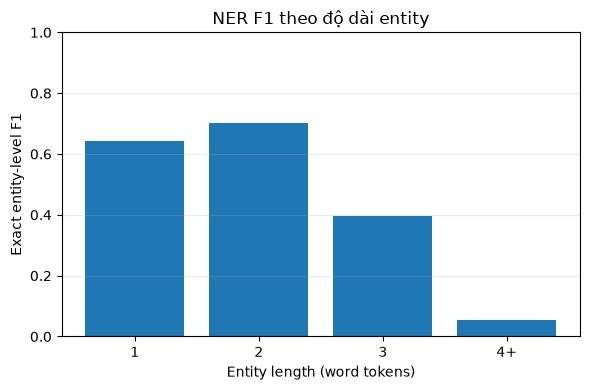

In [14]:
length_scores=entity_length_metrics(transformer_test['entity_result'])
length_table=pd.DataFrame([{'entity_length':length,**scores} for length,scores in length_scores.items()])
display(length_table)
fig,ax=plt.subplots(figsize=(6,4))
ax.bar(length_table['entity_length'],length_table['f1'])
ax.set(xlabel='Entity length (word tokens)',ylabel='Exact entity-level F1',title='NER F1 theo độ dài entity')
ax.set_ylim(0,1); ax.grid(axis='y',alpha=.25); fig.tight_layout()
fig.savefig(LAB_DIR/'entity_length_analysis.png',dpi=160); plt.show()

**Nhận xét Experiment 5:**

Entity F1 là 0,6420 cho entity 1 token, 0,7017 cho 2 tokens, 0,3966 cho 3 tokens và 0,0533 cho 4+ tokens. Xu hướng giảm rõ ở nhóm 3+; nhóm 4+ chỉ có 62 gold entities nên cần đọc kèm support.

## 14. Confusion matrix theo word-level BIO labels

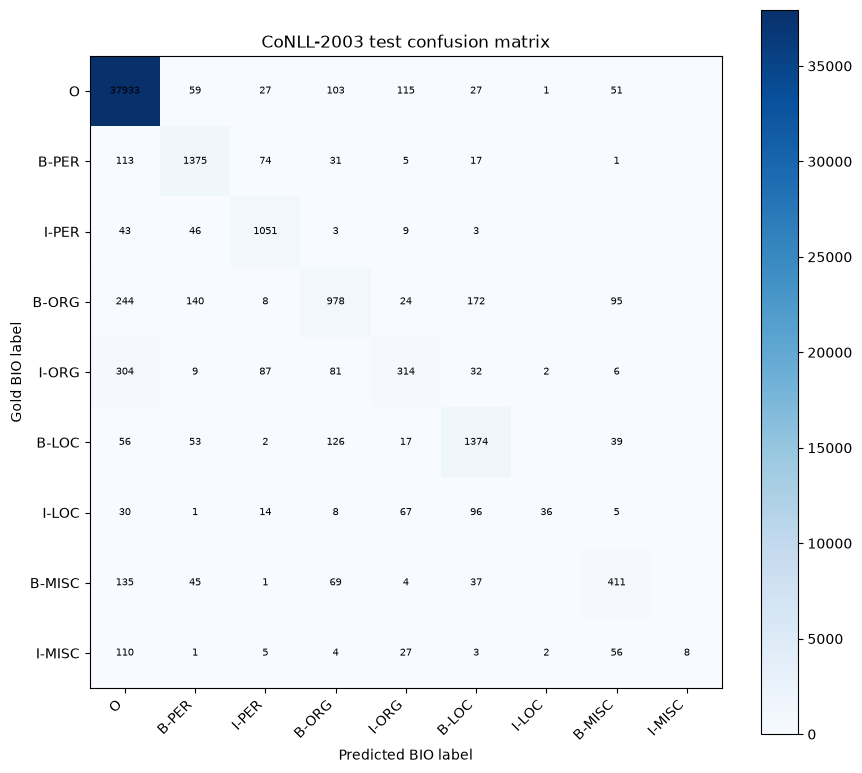

In [15]:
gold_flat=[tag for sent in transformer_test['gold_tags'] for tag in sent]
pred_flat=[tag for sent in transformer_test['predicted_tags'] for tag in sent]
cm=confusion_matrix(gold_flat,pred_flat,labels=LABEL_NAMES)
fig,ax=plt.subplots(figsize=(9,8)); image=ax.imshow(cm,cmap='Blues')
for (i,j),value in np.ndenumerate(cm):
    if value: ax.text(j,i,str(value),ha='center',va='center',fontsize=7)
ax.set_xticks(range(len(LABEL_NAMES)),labels=LABEL_NAMES,rotation=45,ha='right')
ax.set_yticks(range(len(LABEL_NAMES)),labels=LABEL_NAMES)
ax.set(xlabel='Predicted BIO label',ylabel='Gold BIO label',title='CoNLL-2003 test confusion matrix')
fig.colorbar(image,ax=ax); fig.tight_layout(); fig.savefig(LAB_DIR/'confusion_matrix.png',dpi=160); plt.show()

**Nhận xét confusion matrix:**

Word-level token accuracy của Transformer là 0,9366, trong khi exact entity F1 là 0,6463. Một số token được gán đúng nhưng nếu boundary hoặc BIO type sai thì cả entity vẫn bị tính sai.

## 15. Error analysis — 5 FP, 5 FN, 5 boundary errors

In [16]:
gold_spans=transformer_test['entity_result']['gold_spans']
pred_spans=transformer_test['entity_result']['predicted_spans']
fp_spans=sorted(pred_spans-gold_spans)[:5]
fn_spans=sorted(gold_spans-pred_spans)[:5]
boundary= find_boundary_errors(transformer_test['gold_words'],
                               transformer_test['gold_tags'],
                               transformer_test['predicted_tags'])[:5]

def span_description(words,start,end,entity_type):
    return {'text':' '.join(words[start:end]),'type':entity_type,'start':start,'end':end}
error_rows=[]
for group,spans in [('False positive',fp_spans),('False negative',fn_spans)]:
    for sentence_id,start,end,entity_type in spans:
        words=transformer_test['gold_words'][sentence_id]
        same_sentence_gold=[s for s in gold_spans if s[0]==sentence_id]
        same_sentence_pred=[s for s in pred_spans if s[0]==sentence_id]
        if group=='False positive':
            overlap=any(start<g_end and g_start<end for _,g_start,g_end,_ in same_sentence_gold)
            error_type='Wrong type/boundary' if overlap else 'Spurious entity'
        else:
            overlap=any(start<p_end and p_start<end for _,p_start,p_end,_ in same_sentence_pred)
            error_type='Wrong boundary/type' if overlap else 'Missing entity'
        error_rows.append({'error_group':group,'text':' '.join(words),
            'gold_entity':span_description(words,start,end,entity_type) if group=='False negative' else None,
            'predicted_entity':span_description(words,start,end,entity_type) if group=='False positive' else None,
            'error_type':error_type})
for item in boundary:
    error_rows.append({'error_group':'Boundary error','text':' '.join(item['words']),
        'gold_entity':item['gold'],'predicted_entity':item['predicted'],'error_type':'Wrong boundary'})
error_examples=pd.DataFrame(error_rows)
display(error_examples)
print('Counts:',error_examples['error_group'].value_counts().to_dict())

,error_group,text,gold_entity,predicted_entity,error_type
0,False positive,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...",None,"{'text': 'CHINA', 'type': 'LOC', 'start': 7, '...",Wrong type/boundary
1,False positive,"AL-AIN , United Arab Emirates 1996-12-06",None,"{'text': 'United', 'type': 'LOC', 'start': 2, ...",Wrong type/boundary
2,False positive,"AL-AIN , United Arab Emirates 1996-12-06",None,"{'text': 'Arab', 'type': 'LOC', 'start': 3, 'e...",Wrong type/boundary
3,False positive,"AL-AIN , United Arab Emirates 1996-12-06",None,"{'text': 'Emirates', 'type': 'LOC', 'start': 4...",Wrong type/boundary
4,False positive,Japan began the defence of their Asian Cup tit...,None,"{'text': 'Asian', 'type': 'MISC', 'start': 6, ...",Wrong type/boundary
5,False negative,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...","{'text': 'CHINA', 'type': 'PER', 'start': 7, '...",None,Wrong boundary/type
6,False negative,"AL-AIN , United Arab Emirates 1996-12-06","{'text': 'United Arab Emirates', 'type': 'LOC'...",None,Wrong boundary/type
7,False negative,Japan began the defence of their Asian Cup tit...,"{'text': 'Asian Cup', 'type': 'MISC', 'start':...",None,Wrong boundary/type
8,False negative,China controlled most of the match and saw sev...,"{'text': 'Uzbek', 'type': 'MISC', 'start': 16,...",None,Wrong boundary/type
9,False negative,Despite winning the Asian Games title two year...,"{'text': 'Asian Games', 'type': 'MISC', 'start...",None,Wrong boundary/type


Counts: {'False positive': 5, 'False negative': 5, 'Boundary error': 5}


**Ghi chú error analysis:**

Bảng chọn đủ 5 FP, 5 FN và 5 boundary errors. Các ví dụ gồm nhầm CHINA giữa PER/LOC, tách United Arab Emirates thành các span đơn, cắt Asian Cup và bỏ sót Uzbek.

## 16. Context analysis — cùng surface form, khác entity type

In [17]:
surface_forms=defaultdict(list)
for sentence_id,row in enumerate(dataset['test']):
    words=row['tokens']; tags=[LABEL_NAMES[int(x)] for x in row['ner_tags']]
    for entity in bio_to_spans(words,tags):
        surface=entity['text'].casefold()
        surface_forms[surface].append({'sentence_id':sentence_id,'text':' '.join(words),
                                       'entity_type':entity['type']})
context_rows=[]
for surface,mentions in surface_forms.items():
    types=sorted({mention['entity_type'] for mention in mentions})
    if len(types)>1:
        context_rows.append({'surface_form':surface,'types':types,'examples':mentions[:3]})
context_examples=pd.DataFrame(context_rows).sort_values('surface_form').head(10)
display(context_examples)

,surface_form,types,examples
46,american,"[MISC, ORG]","[{'sentence_id': 490, 'text': 'AMERICAN FOOTBA..."
34,arizona,"[LOC, ORG]","[{'sentence_id': 421, 'text': 'Philadelphia , ..."
36,atlanta,"[LOC, ORG]","[{'sentence_id': 451, 'text': 'ATLANTA 10 8 .5..."
63,bangkok,"[LOC, MISC]","[{'sentence_id': 2262, 'text': 'BANGKOK 1996-1..."
1,barcelona,"[LOC, ORG]","[{'sentence_id': 146, 'text': 'FIFA 's players..."
11,boston,"[LOC, ORG]","[{'sentence_id': 363, 'text': 'BOSTON 10 11 4 ..."
10,buffalo,"[LOC, ORG]","[{'sentence_id': 362, 'text': 'BUFFALO 13 12 1..."
59,busang,"[LOC, ORG]","[{'sentence_id': 1161, 'text': 'Analysts and a..."
56,cardiff,"[LOC, ORG]","[{'sentence_id': 1048, 'text': 'Wales grappled..."
2,charleroi,"[LOC, ORG]","[{'sentence_id': 174, 'text': 'Charleroi ( Bel..."


**Nhận xét Context Analysis:**

Cùng surface form có thể mang nhãn khác theo ngữ cảnh: Arizona là ORG trong câu lịch thi đấu nhưng LOC ở dòng “DALLAS AT ARIZONA”; Atlanta là ORG trong bảng điểm nhưng LOC trong câu về tòa appeals.

## 17. Application — Information Extraction (News)

Chọn Option A: trích PERSON, ORGANIZATION và LOCATION từ 30 câu test; MISC được bỏ khỏi IE metric.

In [18]:
IE_SIZE=30
ie_words=transformer_test['gold_words'][:IE_SIZE]
ie_gold_tags=transformer_test['gold_tags'][:IE_SIZE]
ie_pred_tags=transformer_test['predicted_tags'][:IE_SIZE]
IE_TYPES={"PER","ORG","LOC"}  # W9 Option A — News
ie_gold_entities=[[e for e in bio_to_spans(words,tags) if e["type"] in IE_TYPES]
                  for words,tags in zip(ie_words,ie_gold_tags)]
ie_pred_entities=[[e for e in bio_to_spans(words,tags) if e["type"] in IE_TYPES]
                  for words,tags in zip(ie_words,ie_pred_tags)]
ie_metrics=evaluate_information_extraction(ie_pred_entities,ie_gold_entities)
ie_token_metrics=token_metrics(ie_gold_tags,ie_pred_tags)
print('IE exact-entity metrics trên',IE_SIZE,'câu:',ie_metrics)
print('Word-token metrics trên cùng 30 câu:',ie_token_metrics)
ie_examples=[]
for words,entities in zip(ie_words[:5],ie_pred_entities[:5]):
    ie_examples.append({'text':' '.join(words),'extracted':entities_to_dict(entities)})
display(pd.DataFrame(ie_examples))

IE exact-entity metrics trên 30 câu: {'tp': 36, 'fp': 16, 'fn': 17, 'precision': 0.6923076923076923, 'recall': 0.6792452830188679, 'f1': 0.6857142857142857}
Word-token metrics trên cùng 30 câu: {'token_accuracy': 0.9443478260869566, 'token_precision': 0.9443478260869566, 'token_recall': 0.9443478260869566, 'token_f1': 0.9443478260869566, 'token_macro_f1': 0.49043281260856364, 'token_macro_precision': 0.5860525821310135, 'token_macro_recall': 0.47516945788550724}


,text,extracted
0,"SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRI...","{'LOC': ['JAPAN', 'CHINA']}"
1,Nadim Ladki,{'PER': ['Nadim Ladki']}
2,"AL-AIN , United Arab Emirates 1996-12-06","{'LOC': ['AL-AIN', 'United', 'Arab', 'Emirates']}"
3,Japan began the defence of their Asian Cup tit...,"{'LOC': ['Japan', 'Syria'], 'ORG': ['Cup']}"
4,But China saw their luck desert them in the se...,"{'LOC': ['China', 'Uzbekistan']}"


**Nhận xét Information Extraction:**

Trên 30 câu test, pipeline exact-entity đạt precision 0,6923, recall 0,6792 và F1 0,6857. Output được nhóm theo entity type thành structured data; các lỗi span vẫn truyền sang bước IE.

## 18. Lưu metrics và output CSV

In [19]:
results_rows=[]
for name,split_name,metrics,seconds in [
    ('Baseline Logistic Regression','validation',baseline_val_metrics,baseline_training_seconds),
    ('Baseline Logistic Regression','test',baseline_test_metrics,baseline_training_seconds),
    ('Pretrained Transformer','validation',transformer_validation,training_seconds),
    ('Pretrained Transformer','test',transformer_test,training_seconds),
]:
    results_rows.append({'experiment':'Baseline vs Transformer','model':name,'split':split_name,
        'token_accuracy':metrics['token_accuracy'],'token_precision':metrics['token_precision'],
        'token_recall':metrics['token_recall'],'token_f1':metrics['token_f1'],
        'entity_precision':metrics['entity_precision'],'entity_recall':metrics['entity_recall'],
        'entity_f1':metrics['entity_f1'],'training_time_seconds':seconds,
        'max_length':MAX_LENGTH,'batch_size':BATCH_SIZE,'epochs':EPOCHS,
        'learning_rate':LEARNING_RATE,'random_seed':RANDOM_SEED})
results_rows.append({'experiment':'Information Extraction','model':'Pretrained Transformer span extraction',
    'split':'test sample (30 sentences)','token_accuracy':None,'token_precision':None,
    'token_recall':None,'token_f1':None,'entity_precision':ie_metrics['precision'],
    'entity_recall':ie_metrics['recall'],'entity_f1':ie_metrics['f1'],
    'training_time_seconds':None,'max_length':MAX_LENGTH,'batch_size':BATCH_SIZE,
    'epochs':EPOCHS,'learning_rate':LEARNING_RATE,'random_seed':RANDOM_SEED})
results_df=pd.DataFrame(results_rows)
results_df.to_csv(LAB_DIR/'results.csv',index=False,encoding='utf-8-sig')
display(results_df)
print('Đã lưu results.csv, entity_metrics.csv và hai biểu đồ.')

,experiment,model,split,token_accuracy,token_precision,token_recall,token_f1,entity_precision,entity_recall,entity_f1,training_time_seconds,max_length,batch_size,epochs,learning_rate,random_seed
0,Baseline vs Transformer,Baseline Logistic Regression,validation,0.970017,0.970017,0.970017,0.970017,0.777040,0.866880,0.819505,33.973828,128,32,5,0.00002,42
1,Baseline vs Transformer,Baseline Logistic Regression,test,0.950705,0.950705,0.950705,0.950705,0.678303,0.798159,0.733366,33.973828,128,32,5,0.00002,42
2,Baseline vs Transformer,Pretrained Transformer,validation,0.943848,0.943848,0.943848,0.943848,0.672086,0.702980,0.687186,239.177079,128,32,5,0.00002,42
3,Baseline vs Transformer,Pretrained Transformer,test,0.936564,0.936564,0.936564,0.936564,0.629704,0.663833,0.646318,239.177079,128,32,5,0.00002,42
4,Information Extraction,Pretrained Transformer span extraction,test sample (30 sentences),NaN,NaN,NaN,NaN,0.692308,0.679245,0.685714,NaN,128,32,5,0.00002,42


Đã lưu results.csv, entity_metrics.csv và hai biểu đồ.


## 19. Tổng hợp nhận xét sau khi đọc output

- **Tokenization/alignment:** R=1,224 trong sample 20 câu; continuation subwords được ignore theo first-subword strategy.
- **Baseline và Transformer:** baseline entity F1 0,7334 cao hơn Transformer 0,6463 trong lần chạy này.
- **Entity types:** PER/LOC tốt hơn ORG/MISC ở Transformer.
- **Entity length:** F1 giảm mạnh ở nhóm 3+ tokens; nhóm 4+ có support nhỏ.
- **Errors/context:** thấy nhầm type và span fragmentation ở địa danh nhiều từ, cùng entity hiếm.
- **Information Extraction:** F1 exact entity trên 30 câu là 0,6857.

- **Tokenization:**  
- **Baseline vs Transformer:**  
- **Entity-level / entity type:**  
- **Entity length:**  
- **Error / context analysis:**  
- **Information Extraction:**  